## CTG: avaliação final no conjunto de teste

- Pergunta que estamos buscando pela resposta: Os modelos escolhidos na validação cruzada separam bem exames normais, suspeitos e patológicos em exames que nunca viram? Quantos patológicos eles "erram"(pior caso)?



#### 0. Configuração inicial

In [1]:
import json
import subprocess
import warnings

import matplotlib.pyplot as plt
import numpy as np
from statstech.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from statstech.linear_model import LogisticRegression
from statstech.metrics.classification import confusion_matrix, roc_auc_score
from statstech.model_selection import bootstrap_ci
from statstech.neighbors import KNeighborsClassifier
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import SEED, STYLE, TABLES
from analysis.evaluation import evaluate_classifier
from analysis.io import load_dataset
from analysis.report import save_figure, save_table
from analysis.threshold import predict_with_threshold

plt.style.use(STYLE)

warnings.filterwarnings("ignore", message=".*indefinid.*")

CLASS_NAMES = ["normal", "suspeito", "patológico"]
PATHOLOGICAL = 2
LABELS = {"logistic": "Logística", "lda": "LDA", "qda": "QDA", "knn": "KNN"}

#### 1. Dados 

In [2]:
data = load_dataset("ctg")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

for name, y in [("treino", y_train), ("teste", y_test)]:
    counts = np.bincount(y, minlength=3)
    print(f"{name:6s} {len(y):5d} exames   " + "   ".join(
        f"{c}: {n} ({n / len(y):.1%})" for c, n in zip(CLASS_NAMES, counts)))

treino  1755 exames   normal: 1363 (77.7%)   suspeito: 245 (14.0%)   patológico: 147 (8.4%)
teste    359 exames   normal: 285 (79.4%)   suspeito: 47 (13.1%)   patológico: 27 (7.5%)


#### 2. Decisões antes do teste

##### 2.1 Modelos e Hiperparâmetros

Os hiperparâmetros escolhidos na comparação por validação cruzada estão em `ctg_hiperparametros.json`. Cada modelo é reconstruído a partir do arquivo ajustado no treino. 

In [3]:
with open(TABLES / "ctg_hiperparametros.json", encoding="utf-8") as f:
    best = json.load(f)

MODELS = {
    "logistic": LogisticRegression(),
    "lda": LinearDiscriminantAnalysis(),
    "qda": QuadraticDiscriminantAnalysis(),
    "knn": KNeighborsClassifier(),
}
finalists = {}
for key, model in MODELS.items():
    choice = best[key]
    # A transformação log1p não entrou em nenhum modelo final (ver ctg_models.ipynb).
    assert not choice["uses_log1p"]
    pipeline = Pipeline([("scaler", StandardScaler()), ("model", model)])
    pipeline.set_params(**choice["fixed"], **choice["params"])
    finalists[key] = pipeline.fit(X_train, y_train)
    print(f"{LABELS[key]:10s} {choice['params']}   F1 macro na validação cruzada: "
          f"{choice['f1_macro_cv']:.3f}")

Logística  {'model__alpha': 10}   F1 macro na validação cruzada: 0.780
LDA        {'model__reg_param': 1e-06}   F1 macro na validação cruzada: 0.715
QDA        {'model__reg_param': 0.5}   F1 macro na validação cruzada: 0.733
KNN        {'model__n_neighbors': 15}   F1 macro na validação cruzada: 0.723


##### 2.2 Modelo escolhido

É o modelo de maior F1 macro na validação cruzada.

In [4]:
chosen = max(MODELS, key=lambda key: best[key]["f1_macro_cv"])
print("modelo escolhido:", LABELS[chosen])

modelo escolhido: Logística


##### 2.3 Limiar de decisão 

Deixar passar um exame patológico é muito pior que um alarme falso. Logo, o modelo escolhido marca `patológico` sempre que a probabilidade dessa classe passa de um limiar `t`que foi escolhido no treino por validação cruzada. 

In [5]:
with open(TABLES / "ctg_limiar.json", encoding="utf-8") as f:
    threshold_info = json.load(f)
threshold = threshold_info["threshold"]
assert threshold_info["model"] == chosen, "O limiar foi escolhido para outro modelo."
print(f"limiar para patológico: {threshold:.2f} ({LABELS[chosen]})")

limiar para patológico: 0.11 (Logística)


#### 3. Teste 

`X_test` e `y_test`

(próxima célula para registrar em qual commit o teste foi aberto)

In [6]:
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True, check=True).stdout.strip()
print("teste aberto no commit", commit)

teste aberto no commit db3efbc


##### 3.1 Tabela no teste

Cada modelo prevê o teste uma vez

In [7]:
majority_class = np.bincount(y_train).argmax()
predictions = {"baseline": np.full_like(y_test, majority_class)}
for key, model in finalists.items():
    predictions[key] = model.predict(X_test)
proba_chosen = finalists[chosen].predict_proba(X_test)
predictions["threshold"] = predict_with_threshold(
    proba_chosen, finalists[chosen].classes_, PATHOLOGICAL, threshold)

row_labels = {"baseline": "Referência (majoritária)", **LABELS,
              "threshold": f"{LABELS[chosen]} com limiar {threshold:.2f}"}
table = []
for key, y_pred in predictions.items():
    metrics = evaluate_classifier(y_test, y_pred)
    cv_key = chosen if key == "threshold" else key
    table.append({
        "model": row_labels[key],
        "accuracy": metrics["accuracy"],
        "f1_macro": metrics["f1_macro"],
        "pathological_recall": metrics[f"recall_{PATHOLOGICAL}"],
        "pathological_precision": metrics[f"precision_{PATHOLOGICAL}"],
        "f1_macro_cv": best[cv_key]["f1_macro_cv"] if cv_key in best else float("nan"),
    })

print(f"{'modelo':30s} {'acurácia':>8s} {'F1 macro':>8s} {'recall pat.':>11s} "
      f"{'precisão pat.':>13s} {'F1 macro (vc)':>13s}")
for row in table:
    print(f"{row['model']:30s} {row['accuracy']:8.3f} {row['f1_macro']:8.3f} "
          f"{row['pathological_recall']:11.3f} {row['pathological_precision']:13.3f} "
          f"{row['f1_macro_cv']:13.3f}")

save_table([{k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}
            for row in table], "ctg_teste")

modelo                         acurácia F1 macro recall pat. precisão pat. F1 macro (vc)
Referência (majoritária)          0.794    0.295       0.000         0.000           nan
Logística                         0.891    0.774       0.741         0.645         0.780
LDA                               0.852    0.714       0.593         0.696         0.715
QDA                               0.797    0.650       0.481         0.481         0.733
KNN                               0.861    0.725       0.741         0.526         0.723
Logística com limiar 0.11         0.819    0.649       0.926         0.357         0.780


PosixPath('/home/al.dulce.costa/Desktop/statstech-analise/results/tables/ctg_teste.csv')

#### 4. Matriz de confusão do modelo escolhido, com o limiar

[[250   6  29]
 [ 12  19  16]
 [  1   1  25]]


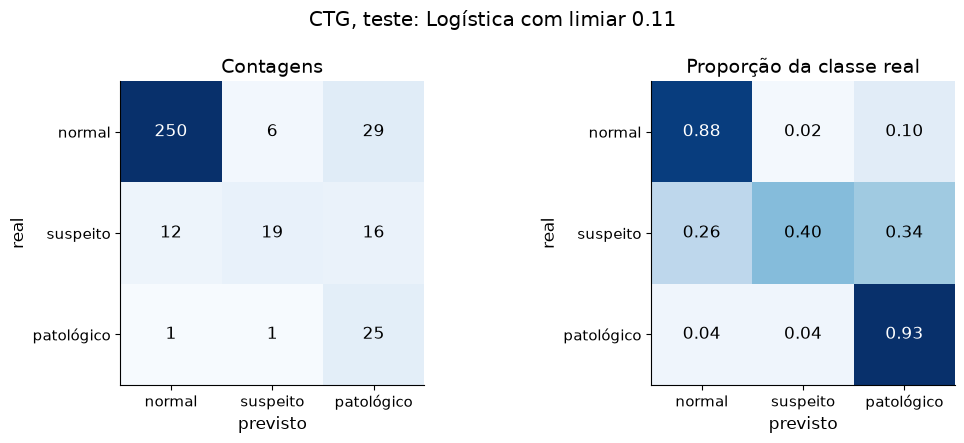

In [8]:
final_pred = predictions["threshold"]
cm = np.array(confusion_matrix(y_test.tolist(), final_pred.tolist(), [0, 1, 2]))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
print(cm)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, matrix, title, fmt in [(axes[0], cm, "Contagens", "d"),
                               (axes[1], cm_norm, "Proporção da classe real", ".2f")]:
    ax.imshow(matrix, cmap="Blues", vmin=0)
    for i in range(3):
        for j in range(3):
            color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", color=color)
    ax.set_xticks(range(3), CLASS_NAMES)
    ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
    ax.set_title(title)
    ax.grid(False)
fig.suptitle(f"CTG, teste: {row_labels['threshold']}")
fig.tight_layout()
save_figure(fig, "ctg_confusao")
plt.show()

#### 5. Intervalos de confiança por bootstrap

In [9]:
def f1_macro(y_true, y_pred):
    return evaluate_classifier(y_true, y_pred)["f1_macro"]


def pathological_recall(y_true, y_pred):
    return evaluate_classifier(y_true, y_pred)[f"recall_{PATHOLOGICAL}"]


intervals = []
for metric_name, metric in [("f1_macro", f1_macro), ("pathological_recall", pathological_recall)]:
    estimate, low, high = bootstrap_ci((y_test, final_pred), metric,
                                       n_bootstrap=1000, random_state=SEED)
    intervals.append({"metric": metric_name, "estimate": float(estimate),
                      "low": float(low), "high": float(high)})
    print(f"{metric_name:20s} {estimate:.3f}   IC 95%: [{low:.3f}, {high:.3f}]")

save_table([{k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}
            for row in intervals], "ctg_teste_intervalos")

f1_macro             0.649   IC 95%: [0.582, 0.711]
pathological_recall  0.926   IC 95%: [0.818, 1.000]


PosixPath('/home/al.dulce.costa/Desktop/statstech-analise/results/tables/ctg_teste_intervalos.csv')

O bootstrap acima trata cada exame como independente mas como os exames do teste vêm de poucos registros, e segmentos do mesmo registro são parecidos, o resultado acaba sendo otimista para o que de fato aconteceria.

#### 6. AUC do patológico 

Mede se o modelo dá probabilidade de patológico maior aos exames patológicos do que aos outros, sem depender do limiar.

In [10]:
auc = roc_auc_score(y_test, proba_chosen, class_k=PATHOLOGICAL)
print(f"AUC patológico contra os outros ({LABELS[chosen]}): {auc:.3f}")

AUC patológico contra os outros (Logística): 0.970


#### 7. Conclusão

**Escolha do modelo.** A Regressão Logística foi escolhida antes de abrir o teste, por ter o maior F1 macro na validação cruzada (0,780).

**Efeito do limiar.** Com o limiar de 0,11 para patológico, o recall sobe de 0,741 para 0,926. Dos 27 exames patológicos do teste, o modelo deixa de detectar apenas 2 (antes eram 7). O custo é a precisão, que cai para 0,357: a maior parte dos alarmes de patológico são falsos. O F1 macro cai de 0,774 para 0,650 e a acurácia de 0,891 para 0,819. Essa queda era esperada, porque o limiar foi escolhido justamente para priorizar não perder patológicos, e não para maximizar o F1.

**Incerteza.** O recall de patológicos tem IC 95% de [0,82; 1,00] e o F1 macro de [0,58; 0,71]. O recall é pouco preciso porque há só 27 patológicos no teste. No pior caso plausível, o modelo perde cerca de 18% dos patológicos, e não apenas os 7% observados.

**Limitações.** (i) O teste tem poucos patológicos, e por isso os intervalos são largos. (ii) Com 359 exames não dá para afirmar que a Logística é melhor que KNN ou LDA, pois as diferenças entre os modelos são pequenas perto da incerteza. (iii) A precisão baixa implica muitos exames normais ou suspeitos reencaminhados, o que só é aceitável se o custo de um alarme falso for bem menor que o de um patológico perdido.

 Ademais, o modelo separa bem os exames em dados novos. Com o limiar, ele detecta a grande maioria dos patológicos (recall 0,93, IC [0,82; 1,00]), ao custo de muitos alarmes falsos (precisão 0,36). Serve como triagem, e não como diagnóstico.
